# CharacterBox U/S/P Results Dashboard

One section per hypothesis (H1 consistency, H2 realism, H3 decline rate), built on a shared
pre-processing step. Re-run `evaluate.py`, then re-run this notebook top to bottom to refresh.

**Primary comparison:** P vs S. **Secondary:** S vs U, P vs U (`docs/research-contract.md` §6).

## 0. Data cleaning & pre-processing

In [85]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

REPO_ROOT = Path.cwd().parent  # this notebook lives in notebooks/, one level under the repo root
H1_PATH = REPO_ROOT / "output" / "evaluation" / "h1_consistency.jsonl"
H2_PATH = REPO_ROOT / "output" / "evaluation" / "h2_realism.jsonl"
PILOT_PATH = REPO_ROOT / "data" / "research_annotations" / "characterbox_pilot.json"

CONDITION_ORDER = ["U", "S", "P"]
CONDITION_COLORS = {"U": "#3498db", "S": "#9b59b6", "P": "#e67e22"}
DECISION_ORDER = ["PASS", "FAIL", "NA"]
DECISION_COLORS = {"PASS": "#2ecc71", "FAIL": "#e74c3c", "NA": "#bdc3c7"}
METRIC_COLUMNS = {
    "Context Use": "decisions.context_use.decision",
    "World Consistency": "decisions.world_consistency.decision",
    "No Contradiction": "decisions.no_contradiction.decision",
}

In [86]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


h1_records = load_jsonl(H1_PATH)
h2_records = load_jsonl(H2_PATH)
print(f"H1 rows: {len(h1_records)}   H2 rows: {len(h2_records)}")

H1 rows: 186   H2 rows: 105


### Trial categories

Pulled from each trial's `note` field in the pilot manifest (`docs/characterbox-provenance.md`,
2026-09-01 entries), not hardcoded here, so this stays correct if the pilot content changes.

In [87]:
with open(PILOT_PATH, encoding="utf-8") as file:
    pilot = json.load(file)

CATEGORY_PATTERN = re.compile(r"Category:\s*([^.]+)\.")

trial_category = {}
for trial in pilot["trials"]:
    note = trial.get("note", "")
    match = CATEGORY_PATTERN.search(note)
    trial_category[trial["trial_id"]] = match.group(1).strip() if match else "uncategorised"

trial_category

{'cb_hp_019_luna_neville_t01': 'normal fact check',
 'cb_hp_019_luna_neville_t02': 'normal fact check',
 'cb_hp_019_luna_neville_t03': 'normal fact check',
 'cb_hp_019_luna_neville_t04': 'normal fact check',
 'cb_hp_019_luna_neville_t05': 'stress fact check (false premise)',
 'cb_hp_019_luna_neville_t06': 'stress fact check (false premise)',
 'cb_hp_019_luna_neville_t07': 'stress fact check (false premise)',
 'cb_hp_019_luna_neville_t08': 'out of bound knowledge fact check (false premise)',
 'cb_hp_019_luna_neville_t09': 'open-ended',
 'cb_hp_019_luna_neville_t10': 'open-ended',
 'cb_hp_019_luna_neville_t11': 'multi-turn'}

In [88]:
h1_df = pd.json_normalize(h1_records)
h1_df["category"] = h1_df["trial_id"].map(trial_category)
h1_df["context_condition"] = pd.Categorical(
    h1_df["context_condition"], categories=CONDITION_ORDER, ordered=True
)
for column in METRIC_COLUMNS.values():
    h1_df[column] = pd.Categorical(h1_df[column], categories=DECISION_ORDER, ordered=True)

h2_df = pd.json_normalize(h2_records)
h2_df["category"] = h2_df["trial_id"].map(trial_category)
h2_df["context_condition"] = pd.Categorical(
    h2_df["context_condition"], categories=CONDITION_ORDER, ordered=True
)

h1_df[["trial_id", "context_condition", "round", "category", "consistency"]].head()

,trial_id,context_condition,round,category,consistency
0,cb_hp_019_luna_neville_t01,U,1,normal fact check,1.0
1,cb_hp_019_luna_neville_t01,S,1,normal fact check,1.0
2,cb_hp_019_luna_neville_t01,P,1,normal fact check,1.0
3,cb_hp_019_luna_neville_t02,U,1,normal fact check,1.0
4,cb_hp_019_luna_neville_t02,S,1,normal fact check,1.0


### Runs

`generation_run_id` is `<pilot_id>-<time.time_ns()>` (see `simulator.py:run_pilot_conditions`),
so the timestamp is genuinely parseable, not guessed. Keeping this as its own table now, with
`generation_run_id` never dropped from `h1_df`/`h2_df`, means later runs slot in without
redesigning anything below.

In [89]:
def parse_run_started_at(generation_run_id):
    try:
        _, nanoseconds = generation_run_id.rsplit("-", 1)
        return pd.Timestamp(int(nanoseconds), unit="ns")
    except (ValueError, AttributeError):
        return pd.NaT


run_pilot = (
    h1_df[["generation_run_id", "pilot_id"]]
    .drop_duplicates(subset="generation_run_id")
    .set_index("generation_run_id")["pilot_id"]
)

runs_df = pd.DataFrame({
    "generation_run_id": sorted(set(h1_df["generation_run_id"]) | set(h2_df["generation_run_id"])),
})
runs_df["pilot_id"] = runs_df["generation_run_id"].map(run_pilot)
runs_df["run_started_at"] = runs_df["generation_run_id"].map(parse_run_started_at)
runs_df["n_trials"] = runs_df["generation_run_id"].map(
    h1_df.groupby("generation_run_id")["trial_id"].nunique()
)
runs_df["h1_rows"] = runs_df["generation_run_id"].map(h1_df.groupby("generation_run_id").size()).fillna(0).astype(int)
runs_df["h2_rows"] = runs_df["generation_run_id"].map(h2_df.groupby("generation_run_id").size()).fillna(0).astype(int)
runs_df = runs_df.sort_values("run_started_at").reset_index(drop=True)
runs_df

,generation_run_id,pilot_id,run_started_at,n_trials,h1_rows,h2_rows
0,cb_hp_019_luna_neville-1790114709698638000,cb_hp_019_luna_neville,2026-09-22 22:05:09.698638,11,60,33
1,cb_hp_012_newt_mcgonagall-1790123909263194000,cb_hp_012_newt_mcgonagall,2026-09-23 00:38:29.263194,13,66,39
2,cb_hp_031_dumbledore_harry-1790133518139879000,cb_hp_031_dumbledore_harry,2026-09-23 03:18:38.139879,11,60,33


In [90]:
# "latest" | "all" | "average" — "all"/"average" only start to matter once a second run
# exists; today there is exactly one, so all three modes currently select the same rows.
RUN_MODE = "latest"


def select_run(df, mode=RUN_MODE):
    if mode == "latest":
        latest_run_id = runs_df.sort_values("run_started_at")["generation_run_id"].iloc[-1]
        return df[df["generation_run_id"] == latest_run_id]
    if mode in ("all", "average"):
        return df
    raise ValueError(f"Unknown RUN_MODE: {mode!r}")


h1_active = select_run(h1_df, RUN_MODE)
h2_active = select_run(h2_df, RUN_MODE)
print(
    f"RUN_MODE={RUN_MODE!r} -> {h1_active['generation_run_id'].nunique()} run(s), "
    f"{len(h1_active)} H1 rows, {len(h2_active)} H2 rows"
)

RUN_MODE='latest' -> 1 run(s), 60 H1 rows, 33 H2 rows


## 1. H1 — Consistency

### Per-condition metric breakdown

One graph per condition; each bar is one metric, 100%-stacked by decision (PASS/FAIL/NA), with
raw counts labeled on each segment. N is small enough right now that a percentage alone would
overstate precision — the counts keep that visible.

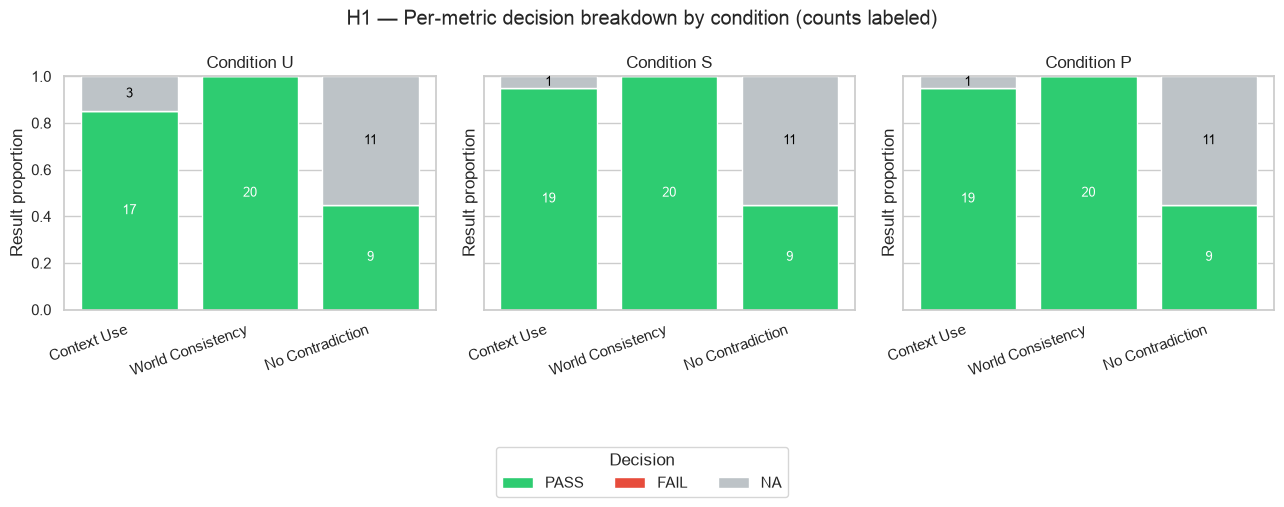

In [91]:
def metric_decision_counts(df, condition):
    condition_df = df[df["context_condition"] == condition]
    counts = pd.DataFrame({
        label: condition_df[column].value_counts().reindex(DECISION_ORDER, fill_value=0)
        for label, column in METRIC_COLUMNS.items()
    }).T
    return counts[DECISION_ORDER]


fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)

for ax, condition in zip(axes, CONDITION_ORDER):
    counts = metric_decision_counts(h1_active, condition)
    proportions = counts.div(counts.sum(axis=1), axis=0)

    bottom = pd.Series(0.0, index=proportions.index)
    for decision in DECISION_ORDER:
        ax.bar(
            proportions.index, proportions[decision], bottom=bottom,
            color=DECISION_COLORS[decision], label=decision,
        )
        for metric in proportions.index:
            height = proportions.loc[metric, decision]
            count = counts.loc[metric, decision]
            if height > 0:
                ax.text(
                    metric, bottom[metric] + height / 2, str(int(count)),
                    ha="center", va="center", fontsize=9,
                    color="black" if decision == "NA" else "white",
                )
        bottom = bottom + proportions[decision]

    ax.set_title(f"Condition {condition}")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Result proportion")
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Decision", loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("H1 — Per-metric decision breakdown by condition (counts labeled)")
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

### Combined consistency score by condition

The single averaged H1 outcome (`evaluate.py:compute_consistency`, N/A-excluded per turn). Bar
height is the mean; `n=` is how many turns actually had a non-N/A score contributing to it.

In [92]:
h1_summary = (
    h1_active.groupby("context_condition", observed=True)["consistency"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "mean_consistency", "count": "turns_scored"})
    .loc[CONDITION_ORDER]
)
h1_summary

,mean_consistency,turns_scored
context_condition,,
U,1.0,20
S,1.0,20
P,1.0,20


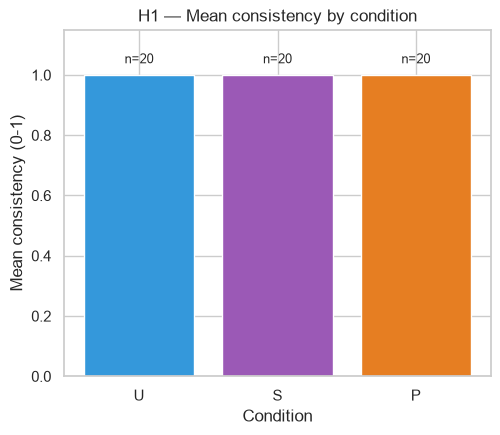

In [93]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
bars = ax.bar(h1_summary.index, h1_summary["mean_consistency"], color=[CONDITION_COLORS[c] for c in CONDITION_ORDER])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Mean consistency (0-1)")
ax.set_xlabel("Condition")
ax.set_title("H1 — Mean consistency by condition")
for bar, n in zip(bars, h1_summary["turns_scored"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03,
        f"n={int(n)}", ha="center", va="bottom", fontsize=9,
    )
plt.show()

### Caveats

- One pilot (one scene, one NPC): 9 single/near-single-turn trials plus one 10-round trial —
  a pipeline sanity check, not a result.
- Small N: several per-condition metric counts are single digits. Read the stacked-bar counts,
  not just the proportions.
- `RUN_MODE = "latest"` currently only selects one run because only one exists — see the
  `runs_df` table above for what's actually loaded.

## 2. H2 — Realism

### Per-dimension breakdown

CharacterBox's seven metrics, one grouped bar chart with all three conditions together (unlike
H1's per-condition subplots — there's no 100%-stacking requirement here, so one chart is easier
to compare across conditions). Error bars are standard error across the 9 trials. Unlike H1,
there's no N/A here: every trial gets a full 1–5 score on all 7 metrics, so n=9 for every bar.

In [94]:
score_columns = [column for column in h2_active.columns if column.startswith("scores.")]

dimension_mean = (
    h2_active.groupby("context_condition", observed=True)[score_columns]
    .mean()
    .rename(columns=lambda c: c.replace("scores.", ""))
    .loc[CONDITION_ORDER]
)
dimension_sem = (
    h2_active.groupby("context_condition", observed=True)[score_columns]
    .sem()
    .rename(columns=lambda c: c.replace("scores.", ""))
    .loc[CONDITION_ORDER]
)
dimension_mean

,Knowledge Accuracy,Emotional Expression,Personality Traits,Behavioral Accuracy,Immersion,Adaptability,Behavioral Coherence
context_condition,,,,,,,
U,3.545455,2.727273,3.090909,2.909091,2.818182,2.727273,3.000000
S,3.727273,3.090909,4.090909,3.454545,3.272727,3.272727,3.363636
P,3.909091,3.181818,3.727273,3.363636,3.090909,3.363636,3.363636


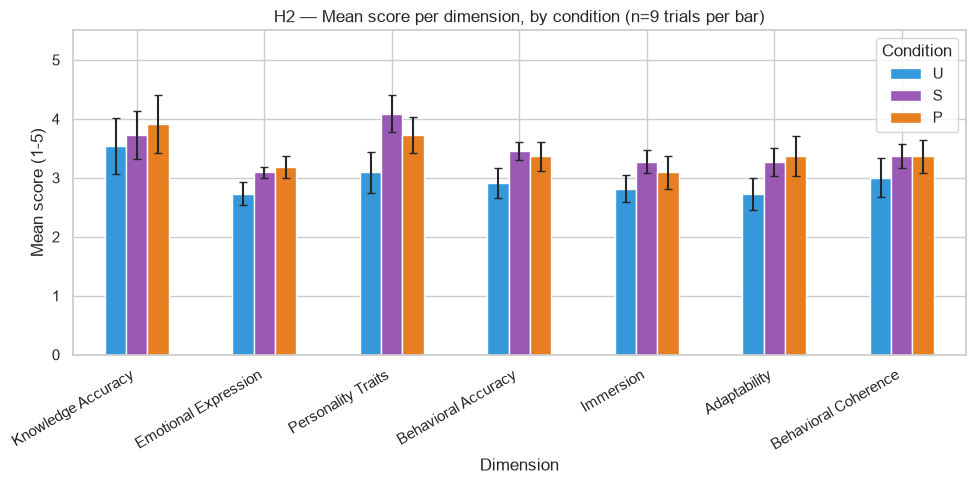

In [95]:
fig, ax = plt.subplots(figsize=(10, 5))
dimension_mean.T.plot(
    kind="bar", yerr=dimension_sem.T, ax=ax, capsize=3,
    color=[CONDITION_COLORS[c] for c in CONDITION_ORDER],
)
ax.set_ylim(0, 5.5)
ax.set_ylabel("Mean score (1-5)")
ax.set_xlabel("Dimension")
ax.set_title("H2 — Mean score per dimension, by condition (n=9 trials per bar)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Condition")
plt.tight_layout()
plt.show()

### Combined realism score by condition

The single averaged H2 outcome (`evaluate.py:evaluate_h2_trial`, unweighted mean of the 7
dimensions). Bar height is the mean; error bars are standard error across trials; `n=` is
trials scored (constant at 9 here, but will vary once trial counts differ by condition — they
can't currently, since every condition runs the same trial set).

In [96]:
h2_summary = (
    h2_active.groupby("context_condition", observed=True)["average"]
    .agg(["mean", "sem", "count"])
    .rename(columns={"mean": "mean_realism", "sem": "sem_realism", "count": "trials_scored"})
    .loc[CONDITION_ORDER]
)
h2_summary

,mean_realism,sem_realism,trials_scored
context_condition,,,
U,2.974026,0.266091,11
S,3.467532,0.185855,11
P,3.428571,0.254094,11


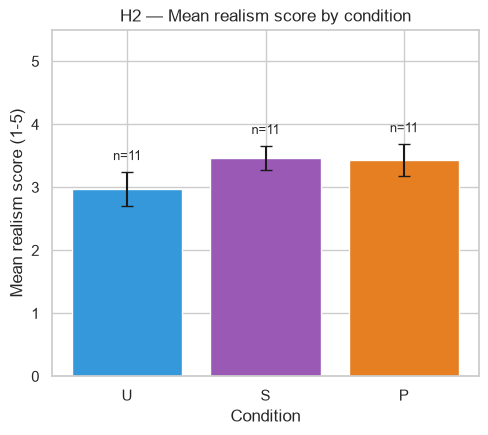

In [97]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
bars = ax.bar(
    h2_summary.index, h2_summary["mean_realism"],
    yerr=h2_summary["sem_realism"], capsize=4,
    color=[CONDITION_COLORS[c] for c in CONDITION_ORDER],
)
ax.set_ylim(0, 5.5)
ax.set_ylabel("Mean realism score (1-5)")
ax.set_xlabel("Condition")
ax.set_title("H2 — Mean realism score by condition")
for bar, (_, row) in zip(bars, h2_summary.iterrows()):
    label_y = row["mean_realism"] + row["sem_realism"] + 0.15
    ax.text(
        bar.get_x() + bar.get_width() / 2, label_y,
        f"n={int(row['trials_scored'])}", ha="center", va="bottom", fontsize=9,
    )
plt.show()

### Caveats

- Same single-pilot caveat as H1: 9 trials per condition, one scene, one NPC — a pipeline
  sanity check, not a result.
- Error bars are standard error across trials, not a significance test — with n=9 per
  condition, don't read small mean differences as reliable yet.
- `RUN_MODE` (set in the pre-processing section) applies here too via `h2_active`.

## 3. H3 — Decline rate (exploratory)

`docs/research-contract.md` §7's exploratory extension. Only trials with more than one round
qualify — right now that's just `t10`, selected by round count rather than a hardcoded trial
ID, so this keeps working automatically if more multi-turn trials get added later.

In [98]:
rounds_per_trial = h1_active.groupby("trial_id")["round"].nunique()
multi_turn_trial_ids = rounds_per_trial[rounds_per_trial > 1].index.tolist()

h3_df = h1_active[h1_active["trial_id"].isin(multi_turn_trial_ids)].sort_values(
    ["trial_id", "context_condition", "round"]
)
print("Multi-turn trials found:", multi_turn_trial_ids)

# Averaging across trials means this stays correct with 1 trial (today) or several (later).
multi_turn_curve = (
    h3_df.groupby(["context_condition", "round"], observed=True)["consistency"]
    .mean()
    .reset_index()
)
multi_turn_curve.head()

Multi-turn trials found: ['cb_hp_031_dumbledore_harry_t11']


,context_condition,round,consistency
0,U,1,1.0
1,U,2,1.0
2,U,3,1.0
3,U,4,1.0
4,U,5,1.0


### Consistency over time, with both candidate "decline rate" summaries

The line chart is the data; "decline rate" is just a number summarising it, shown two ways
below the chart so you can pick one:

- **Trend-line slope** (dashed lines, and in the legend): a fitted linear slope per condition.
  Precise, but a raw regression coefficient is exactly the kind of number a "don't want to see
  numbers" audience tends to bounce off.
- **Early vs. late half** (table below): mean consistency in rounds 1–5 vs. 6–10. Less
  statistically formal, but reads immediately without translation.

Dotted vertical lines mark rounds 5 and 8 — `t10`'s two false-premise rounds (from its `note`
field; this is manually set per trial design, not derived from the data, since round *type*
isn't a structured field — update this if a future multi-turn trial uses different rounds).

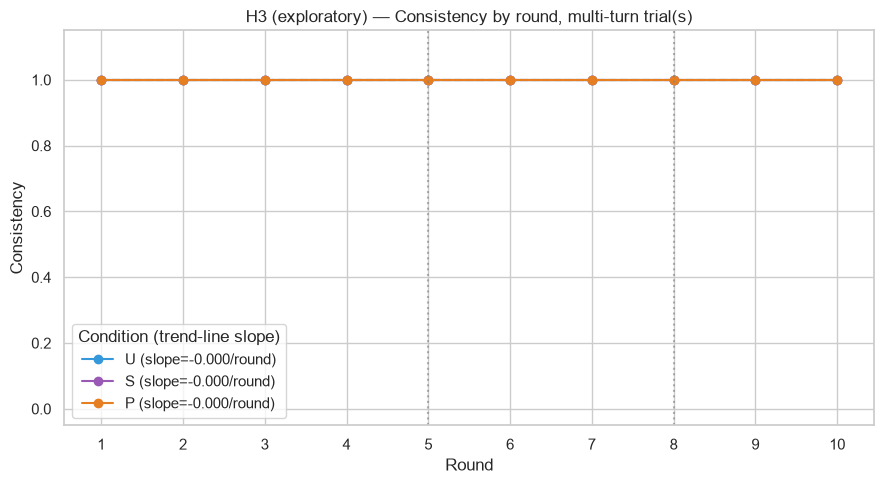

In [99]:
FALSE_PREMISE_ROUNDS = {5, 8}  # t10's design; see data/research_annotations/characterbox_pilot.json

slopes = {}
fig, ax = plt.subplots(figsize=(9, 5))

for condition in CONDITION_ORDER:
    subset = multi_turn_curve[multi_turn_curve["context_condition"] == condition].sort_values("round")
    fit_subset = subset.dropna(subset=["consistency"])
    if len(fit_subset) >= 2:
        slope, intercept = np.polyfit(fit_subset["round"], fit_subset["consistency"], 1)
    else:
        slope, intercept = float("nan"), float("nan")
    slopes[condition] = slope

    label = f"{condition} (slope={slope:+.3f}/round)" if slope == slope else condition
    ax.plot(subset["round"], subset["consistency"], marker="o", label=label, color=CONDITION_COLORS[condition])
    if slope == slope:
        trend_y = slope * fit_subset["round"] + intercept
        ax.plot(fit_subset["round"], trend_y, linestyle="--", color=CONDITION_COLORS[condition], alpha=0.5)

for round_number in FALSE_PREMISE_ROUNDS:
    ax.axvline(round_number, color="grey", linestyle=":", alpha=0.6)

ax.set_xticks(range(1, 11))
ax.set_ylim(-0.05, 1.15)
ax.set_xlabel("Round")
ax.set_ylabel("Consistency")
ax.set_title("H3 (exploratory) — Consistency by round, multi-turn trial(s)")
ax.legend(title="Condition (trend-line slope)")
plt.tight_layout()
plt.show()

In [100]:
EARLY_ROUNDS = range(1, 6)
LATE_ROUNDS = range(6, 11)

early_late = pd.DataFrame({
    "early_mean_r1_5": h3_df[h3_df["round"].isin(EARLY_ROUNDS)]
        .groupby("context_condition", observed=True)["consistency"].mean(),
    "late_mean_r6_10": h3_df[h3_df["round"].isin(LATE_ROUNDS)]
        .groupby("context_condition", observed=True)["consistency"].mean(),
}).loc[CONDITION_ORDER]
early_late["change"] = early_late["late_mean_r6_10"] - early_late["early_mean_r1_5"]
early_late["trend_slope"] = pd.Series(slopes)
early_late

,early_mean_r1_5,late_mean_r6_10,change,trend_slope
context_condition,,,,
U,1.0,1.0,0.0,-4.934884e-17
S,1.0,1.0,0.0,-4.934884e-17
P,1.0,1.0,0.0,-4.934884e-17


### Contradiction summary

Two more of the research contract's named H3 measures — cheap enough to be table cells rather
than separate charts.

In [101]:
NO_CONTRADICTION_COLUMN = "decisions.no_contradiction.decision"


def first_fail_round(df, condition):
    subset = df[(df["context_condition"] == condition) & (df[NO_CONTRADICTION_COLUMN] == "FAIL")]
    return int(subset["round"].min()) if not subset.empty else None


def cumulative_fail_count(df, condition):
    condition_df = df[df["context_condition"] == condition]
    return int((condition_df[NO_CONTRADICTION_COLUMN] == "FAIL").sum())


contradiction_summary = pd.DataFrame({
    "first_fail_round": {c: first_fail_round(h3_df, c) for c in CONDITION_ORDER},
    "cumulative_fail_count": {c: cumulative_fail_count(h3_df, c) for c in CONDITION_ORDER},
}).loc[CONDITION_ORDER]
contradiction_summary

,first_fail_round,cumulative_fail_count
U,None,0
S,None,0
P,None,0


### Caveats

- One 10-round trial. Both "decline rate" numbers above are computed from a single trial's
  curve right now — neither is a reliable rate until more multi-turn trials exist.
- The false-premise round markers (5, 8) are specific to `t10`'s design and manually set;
  they won't automatically apply to a differently-designed multi-turn trial added later.